### Estatística Inferencial

### Preparação

In [1]:
import base64
import hashlib
import io
import json
import zlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

try:
    from IPython.display import display
except ImportError:
    def display(obj):
        print(obj.to_string() if isinstance(obj, (pd.DataFrame, pd.Series)) else obj)

ALFA = 0.05
CONFIANCA = 0.95
SEMENTE = 202509
N_SORTEIOS = 80
LIMIAR_PP = 3.0  # Exclusivamente didático; não é referência regulatória.
GRUPOS = {2: "Privado nacional", 3: "Controle estrangeiro"}
pd.set_option("display.max_columns", 12)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.figsize": (9, 4.6), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})
print("Ambiente pronto. As análises principais funcionam sem acesso à internet.")

Ambiente pronto. As análises principais funcionam sem acesso à internet.


In [2]:
BASE_COMPACTADA = "eNqNWcuO21YS3fdXCFnNABznvh9LSmKrr02RAkl1bG+CThwEBjLuQeLMPqtg9jOb/E7/2JyqS1IdR5Q6D1jtlkp1b1WdR3Hz+CF9+uVz0Tz+8wd68fHzrx+/f3gsPjx8fvj2u4dffiiG77/D/8Xm8cPm8dOPP+F9Pz98eDz8/OuHHz59//Hhp+Lh88d/P377+PPHHz9+wo//+ml+fSOKddls2tW2Xa27sk/1qn9VviqE+1oJ5YrvZCGLjRBBaBULZZwUwUVpXolCBqm1lsK+EjfaCS1ssSnT23JVbdqm3adNubqttlVX1meieR0KpV2QxitlKZoM2nkfFaI54YWUURRpKJ/+WB2blHP8MjOVY4mIzKSLRkTrOJZTwUkdbI5l8KswHhNn3Fb9hVjeFjJaHNQorymWt0rj8B6xojB4T5hi9WUzlA1OuPpbvrq//yWqzlFlQFQlojFaBIoag9dOcVAEF05FMyU47FaHcjMcy3opR61d4Y1WNkSLCIWP1moTKJgNEgcOcc7wtiuXwkiBa7POBW3yrdHplaQCoBjSKjlG2bTtAWUc0j0ipk1XbdNSTG8symqMQBaUmjVBKI9uuVFCB6XV+ZBtu+aIq3+sxsT57858QfBIWmlpqdr4AheD0THQPWrlDE4zfsPbw0KOyqDESkmv0XiSzq0M2ldSjKi8UML500xU/VBu+VWX2tWuo3rTT/1xcVCkNegaFRTqErmzrZVCac7R+IiX0y2kgTr7zWLbRFVwX+NzlKmVwTgdqc7RhiDlVKH7dmiR2pD2S4UxAUnh5PjPKj509ErTyxstg1cm2ikptxADIRBDehm119TEChlggvlcOLDV0729fnV4tdq33a5sFo8mHWIJgU+ZPP4e+fAlGRx5LmNqBszXwqFiRBC8iAHFp0EwuCFN3YbZ0irMc7At323a+8WJkh4ni9H74KyjOM5aTALiICePf0/90LQd8GOoruIlOlQXQQodPU883ZTGzHHxVLBmLt7hzC09n3TcLMpGiBs8YNY4zkt4Ov0XoHabGvxFKvdVM7T9JYxzwWM0I53W4VsEdb9Ba0Z/urNVuS/ft00ql46IrimcRxcF6oLCY9KFp2tDZwCK5zkq15ulyxrbQUtVOIcGNYoRjbBNEnwDhogmpoM2B1xXh6HprwREWoUNHnChaAaNl8JJmhzwgglWh1O3g636tGtozC80vnUSlOColNpZZT1nh1m2fqLQrly3PM7ctA3QrW3QcxcTBTZYoKQDZntBI+6iFVwNxCY8G3uvr3bHbjlBidMqFUGanjlLyRA1B3EOQzE1cLm7hDcaUAOMUQazSLloo2V0gi9NBkDrdND1frdIKj4UFhnhzYHuHRGEpRDR4v5kLA5pcyjfrTiNCe33T3/UQzrUfL6/BgWFqMKA7AD5jDtWY4L4jjwQUcy4s6+6DaFgfWE6pzwBwiBjC/Kg1kX/qWjH1lU0ZhSSBj1P0eoMIVT9IXVpyDqgPUcExhdomRCjkJy2oP5mxLWRcHjqwbrsifCW0Mk5W4BRkZeneVXoGUyeZJiDkFKC6/Jm1d5iYquOhBf+6FJdr+p3zebu3C2fmxlrHX2PiIF5ywFhAD38NdKgKSaGOKSmWkQsbwrtHc1byJoCM2OZWkM0UU1nbru0S82yxomogPZgAu/47jS60ngGBCnB1zP0tZt2v1qv9wuHMk4hIVwRuDQnhO5RhjlLGNQcb5tYuFlmYQVFiZknkrEKUW1gsUWYICcouU3rRbElTdAQHeAVaZh+jTVKsdZVmpovFNvqOPSbu2o1T+g8H2Vd7cv2XMUgqKBkKBgdTpP0I0kIKJe4PXlOxwA/n35bJK3gCio2dD6xslIGgExpeouaApOnlu2e/rNNAwAF7dbW1RU0RjqFgjAShp0DcAB1CazOQdJSzYq6vU39omBVHnmCowVkeNZVHg1HvSVDMDFMyb1u75rVtqq66qLKh9ugZqd8gCawNVwNLyH9v+TV9TpdCQUWYInmkIeVVAKFFhYA9gIBhlRyVZ/d0pdDeYYajFUcGhqC4Vg58GJkjEJTzhQ2CS14kbp6t0iIuGQEU2AUAhFUxFgyODdWQzS5MJ35rgdZL8ySNyiAwz+Qb6PNUiy30IG4SjPD0OYOs31yRX/Bn6/LMxliGCk6BJPk8ip0NVO2hBtE9xRvUje0zZn5OHuJz+sDwIRGlKPNhPTnGQF3+FnujLUuu+3FSiOSAkZSJIEZy4oCTYywUznS++PdJT89FSR6hBMknTkxeGkbKZ4B1aoZbFOzPnZnZmLsEXwIYOIEkIXhzaBp2G8BJANksSkw72WDib9ooQFC+CzcCfqEkwHo5bl3oEhM2jSgCZS4Ly/pVWkEFAe7Pwh8QHiuoYZN9/KMs8KQVt0uHaolTHI4BD4eSQmyddaKVA6wg2bNzuR/vN1d0VoeQog6ScfIlwVi1Z6zC9CKfh77+4suiigEBxsNEBxuNkDG6/maTsBRda8v9pMgIDTZJoIklMhUSTp43syAKfdl6hdPFSMuBX8oRgncFOMPpkgBLGei7NXiqcDKkYRanmpwOD7GFwxkUDNl98c91M6eOnzoj2m86yp17WJmCuUCuku2i9CmxkQOLC36doacvt2kCpZqVzW0LbpGJpDFZKziSOgesVgMwsfCdMxzmJrtsR+6VL5ADQIHCkykjoyNntrXsXrGRfh537Mm83+mT58teWCk0QesniBhAgsNw9skOZUTp0wXdA8gFohMQM1zGANZDgBsQFOg0E17366mHQqkbgOnN0a7DIdTSeClADAkGbiBYWWykAYLyFng07U1u2O9KEkBLgWt1SQ1SkEQwZ0LrUu/nQ1R1WwTe9Gl4zobEQf2gkcAciZo5qQoebs4xqmPffuSdhPQr0qCLBwPAiRjzLtJGo9JuZQAm3oRIiBQClpAeN6sRZClyUYPcgrydQzyDs74Diqb1i7XkR5uDLo6wG1IZl4XePFnUFAYyWlA0VzMbFd2iVKxSrfkUVgY47fUq5bWlFG6gswn8UXZHMq2/lNuL+kQCo34wDUf8nLM86sbgIKGM/JFe+xOLvI6A1M9CpA6KsPaD1cb2ATRztjM8N2123ZdNYtLCyB9oQMm3WoeUaoMb0/R0v60eLq+8tQeYiArDCCSzmseZ50VU9u+2a6vFlWSRdTISpC7KWjDlzcCwSo5G9JnPQueG0XzCHhbUASK/vTfBuh+xtObQIJe2MArKdTW5U072ZeZaMp1A8/XkYesyi41u8U1A+1NI9xiVqkIZzKH4gSwvkW7b9JliQCRAbwAibOOMoTuuYshJN28YLhNzfsXizOcBVl5Wslk5qFeyYqKHiy42WxUF2yBdmSCDGkOTsygvjKvPiKtRk7rrKxKr5BLpAU2bZ8Cq3namXJGoOYTiBzKYw0ltKyD4EXgy4TgGZV4FS23mY9GTLQ3tIen396nRTjDgWCaUGsXGapxO4YH3Y3rCaakLlFrpeYeeiqNe7/qhYvAEGFK6apD3ivEwLQH1ehcnGkvP9TZETVTUS9eH1QjLDbYhR0LLaSoe2mvbmj5jysDz4OVq2o4C0ww81WHvOtzE8ex6YFFzMtGXjHcWBoRkO2z3dTVjR6vqSD/x6cxZAWzs8KdA/AnSEprjG6JcnfVsFQmiOZIj8IcV4cefihemZEr1xYSL21gqE5w8rJdDOwESRva72RZD8mUF+1KA6KnaatvL0IdQBxox8/qkAo9ZrtRKLYVUx+/qdaruxJDcRXuqHpwK9DgvI6BtmRutcYAAE/j3y0aZXZwiCCyUYkQvRQgwhSEWTbrxQ8rsjk2KkZb/FJLFmhAcDiW6ev7qrm9XYQJT9dAzxtYbaM0bH+dIpd5soG02mzr49PvT/+r+nGOqAv6i61EXl2oEcNc5ssI/3rKbA98XjqdDuyVrOXTSXqgwft4R/pb2OKr14fR5G/uyj5viIrVvGAueyIU/umrhUctEVaJRxKzEtRI5wpDPiV4v/iQBcql8CBMNr1W5o2gpN6G5R8//U3bdikb86udFHApQIPIDsrCW/osBgzU2oT4tyUJqyVwtfSkBx5M504Uzo4rakW5TuqfAJGeVb7o8bHXOubnUGYEQZgiTAzeuG7erfZVXefNw2Zxe4orKlx0hhEFFlUwPRL2a/j5WViX91VdvV2UiiiII7TMbR4j8wauJkQQ20Rl1aouAUrtfSKMp5/Xx6oBzpepq/pz04sJRZM73kOTjpX8kEzg0GJu/TSUx7NPB57dE62dAvc5MmWc0woDaGfncFz3V5+GY94IMWNeo4C+VV68w01DCEwTM7TN4j2hzhg6LzMVYHRMfpROK10A5Z/uqSk3GAxAE4wX/FJ57no8SX3DSwEY+fwIXMO9xllofUPPArqGmgnBrkr+EBwYKsr81FbGLHgBP8JM9L+ptsd6eV/s0JRCcTNZmCKRe8kGP98QYdPbtIhLHpRoodZY6Qboybw89xretmDAqPPEXtnOTQ8hDK1wI6/AwfCMAorGrVvP7L2drPviI0OcKBQFWXXckZrGfXcEB0HKLN4G7DA+9X9s77mI"
SHA256_BASE = "d956049c2f038674ab46d177e5b72c8554d6fe1b55cc992f61a3e53cde06ea64"
conteudo = zlib.decompress(base64.b64decode(BASE_COMPACTADA))
assert hashlib.sha256(conteudo).hexdigest() == SHA256_BASE
base_bruta = pd.read_csv(io.BytesIO(conteudo), dtype={
    "CodInst": "string", "data_base": "string",
    "CodConglomeradoPrudencial": "string", "Tc": "Int64"
})
assert len(base_bruta) == 116
assert base_bruta.CodInst.is_unique
assert base_bruta.data_base.eq("06/2026").all()
assert base_bruta.Tcb.eq("b1").all()

escopo = base_bruta.Tc.isin([2, 3])
numeros_validos = (
    np.isfinite(base_bruta.ativo_original) & (base_bruta.ativo_original > 0)
    & np.isfinite(base_bruta.pl_original)
)
base = base_bruta.loc[escopo & numeros_validos].copy()
base["grupo"] = base.Tc.map(GRUPOS)
base["pl_ativo_pct"] = 100 * base.pl_original / base.ativo_original
base = base.sort_values("CodInst").reset_index(drop=True)
assert np.isfinite(base.pl_ativo_pct).all()

auditoria = pd.DataFrame({
    "etapa": ["Recorte B1 incorporado", "TC 2/3",
              "Excluídas por saldo ausente/inválido no escopo", "Base elegível"],
    "quantidade": [len(base_bruta), int(escopo.sum()),
                   int((escopo & ~numeros_validos).sum()), len(base)]
})
excluidas_saldo = base_bruta.loc[escopo & ~numeros_validos,
    ["CodInst", "NomeInstituicao", "Tc", "ativo_original", "pl_original"]]
display(auditoria)
display(excluidas_saldo)

# Simulação de amostragem: o n é de sorteios, não de instituições diferentes.
rng = np.random.default_rng(SEMENTE)
amostras = []
for tc in [2, 3]:
    populacao_grupo = base.loc[base.Tc.eq(tc)]
    indices = rng.choice(len(populacao_grupo), size=N_SORTEIOS, replace=True)
    sorteada = populacao_grupo.iloc[indices].copy()
    sorteada["ordem_sorteio"] = np.arange(1, N_SORTEIOS + 1)
    amostras.append(sorteada)
amostra = pd.concat(amostras, ignore_index=True)
x = amostra.loc[amostra.Tc.eq(2), "pl_ativo_pct"].to_numpy()
y = amostra.loc[amostra.Tc.eq(3), "pl_ativo_pct"].to_numpy()
print(f"Preparação concluída: {len(base)} unidades elegíveis; {len(x)} + {len(y)} sorteios.")

,etapa,quantidade
0,Recorte B1 incorporado,116
1,TC 2/3,107
2,Excluídas por saldo ausente/inválido no escopo,1
3,Base elegível,106


,CodInst,NomeInstituicao,Tc,ativo_original,pl_original
115,31880826,BANCO GUANABARA S.A.,2,NaN,NaN


Preparação concluída: 106 unidades elegíveis; 80 + 80 sorteios.


### Origem e rastreabilidade

## Auditar o recorte e definir o alvo

1. Unidades elegíveis por grupo e as ausências no recorte inicial.
2. Exclusões por saldo ausente/inválido. Seria correto substituí-las por zero?
3. Unidade de análise, variável, população de referência e período.
4. A base traz instituições individuais. Integrantes de um mesmo conglomerado prudencial aparecem em linhas separadas.

In [3]:
def resposta_1(base_bruta, base):
    return base.groupby("grupo").agg(
        unidades=("CodInst", "nunique"),
        observacoes=("CodInst", "size")
    )

r1 = resposta_1(base_bruta, base)
display(r1)
display(base_bruta[["ativo_original", "pl_original"]].isna().sum().rename("ausentes_B1"))
display(excluidas_saldo)
assert r1.unidades.sum() == 106

,unidades,observacoes
grupo,,
Controle estrangeiro,47,47
Privado nacional,59,59


ativo_original    2
pl_original       2
Name: ausentes_B1, dtype: int64

,CodInst,NomeInstituicao,Tc,ativo_original,pl_original
115,31880826,BANCO GUANABARA S.A.,2,NaN,NaN


**Resposta:** há 59 instituições de controle privado nacional e 47 de controle estrangeiro.
Das 116 instituições b1, 107 têm TC 2/3; uma dessas 107 tem saldos ausentes (`NI`)
e é excluída: BANCO GUANABARA S.A.
Os saldos se referem à data-base, não à situação atual dessas instituições.

A unidade é a instituição individual. O alvo é a média de PL/ativo de cada grupo
**entre as 106 instituições elegíveis de junho de 2026**. Zero inventaria um dado;
a ausência também pode ser seletiva. Como integrantes de um mesmo conglomerado prudencial
aparecem em linhas separadas, um grupo econômico pode entrar mais de uma vez na média,
e os balanços de holding e controladas se sobrepõem. A média descreve instituições,
não grupos econômicos; para comparar grupos, agregue pelo conglomerado prudencial.

## Entender a amostra e a distribuição

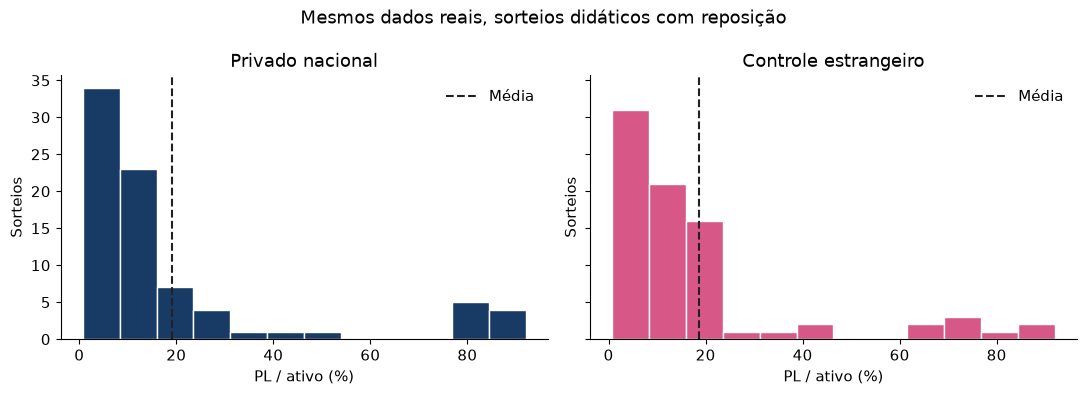

,sorteios,distintas,media_pct,mediana_pct,desvio_pp,minimo_pct,maximo_pct
grupo,,,,,,,
Controle estrangeiro,80,34,18.6443,10.6996,20.5878,3.0605,89.7282
Privado nacional,80,42,19.1555,10.3001,25.3980,0.7031,91.9941


In [4]:
def resposta_2(amostra):
    resumo = amostra.groupby("grupo").agg(
        sorteios=("CodInst", "size"), distintas=("CodInst", "nunique"),
        media_pct=("pl_ativo_pct", "mean"), mediana_pct=("pl_ativo_pct", "median"),
        desvio_pp=("pl_ativo_pct", "std"), minimo_pct=("pl_ativo_pct", "min"),
        maximo_pct=("pl_ativo_pct", "max")
    )
    por_grupo = [amostra.loc[amostra.Tc.eq(tc), "pl_ativo_pct"].to_numpy() for tc in GRUPOS]
    todos = np.concatenate(por_grupo)
    bins = np.linspace(todos.min(), todos.max() + 1e-9, 13)
    fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)
    for ax, valores, nome, cor in zip(axs, por_grupo, GRUPOS.values(), ["#183B66", "#D75887"]):
        ax.hist(valores, bins=bins, color=cor, edgecolor="white")
        ax.axvline(valores.mean(), color="#212121", linestyle="--", label="Média")
        ax.set(title=nome, xlabel="PL / ativo (%)", ylabel="Sorteios")
        ax.legend(frameon=False)
    fig.suptitle("Mesmos dados reais, sorteios didáticos com reposição", fontsize=13)
    fig.tight_layout()
    plt.show()
    return resumo

r2 = resposta_2(amostra)
display(r2)

**Leitura:** a assimetria à direita torna a média sensível às unidades com PL/ativo
alto. Isso não prova erro de registro. A reposição explica as repetições e garante
sorteios independentes da distribuição empírica; não aumenta o número de bancos conhecidos.

Os rótulos de controle são características observadas, não tratamentos sorteados.
A média simples descreve a unidade escolhida ao acaso; ponderar por ativo dá mais
peso às unidades maiores e altera o parâmetro. A distribuição deve ser examinada
antes de interpretar os ICs; tamanho amostral não substitui esse diagnóstico.

## Intervalo de confiança

**Pergunta:** qual é o IC de 95% para a média do grupo privado nacional no desenho didático?

In [5]:
def ic_media(valores, confianca=0.95):
    valores = np.asarray(valores, dtype=float)
    if not 0 < confianca < 1 or len(valores) < 2 or not np.isfinite(valores).all():
        raise ValueError("Forneça ao menos dois valores finitos e confiança entre 0 e 1.")
    n = len(valores)
    media = valores.mean()
    desvio = valores.std(ddof=1)
    erro = desvio / np.sqrt(n)
    critico = stats.t.ppf((1 + confianca) / 2, df=n - 1)
    return dict(n=n, media=media, desvio=desvio, erro_padrao=erro,
                inferior=media-critico*erro, superior=media+critico*erro)

r3 = ic_media(x)
display(pd.DataFrame([r3, ic_media(x, 0.99)], index=["95%", "99%"]))

,n,media,desvio,erro_padrao,inferior,superior
95%,80,19.1555,25.3980,2.8396,13.5035,24.8076
99%,80,19.1555,25.3980,2.8396,11.6604,26.6506


**Resposta:** média amostral de aproximadamente 19,1555%; IC 95% de
13,5035% a 24,8076%. O IC de 99% é mais largo porque exige maior cobertura nominal.

Sob repetições dos sorteios e a aproximação t, cerca de 95% dos intervalos construídos
assim devem cobrir a média fixa da distribuição empírica. O intervalo não descreve
95% das instituições e não atribui probabilidade frequentista ao parâmetro fixo.
O desvio resume dispersão dos valores; o erro-padrão resume variação da média entre amostras.
Com distribuições não normais, o intervalo t é aproximado; veremos sua cobertura adiante.

## Testar uma diferença com Welch

In [6]:
def comparar_welch(x, y, alfa=0.05):
    x, y = np.asarray(x, float), np.asarray(y, float)
    if min(len(x), len(y)) < 2 or not (np.isfinite(x).all() and np.isfinite(y).all()):
        raise ValueError("Cada grupo deve conter ao menos dois valores finitos.")
    if not 0 < alfa < 1:
        raise ValueError("alfa deve estar entre zero e um.")
    a, b = x.var(ddof=1)/len(x), y.var(ddof=1)/len(y)
    if a+b <= 0:
        raise ValueError("Não há variabilidade para estimar o erro-padrão.")
    erro = np.sqrt(a+b)
    gl = (a+b)**2 / (a*a/(len(x)-1) + b*b/(len(y)-1))
    delta = x.mean()-y.mean()
    critico = stats.t.ppf(1-alfa/2, gl)
    teste = stats.ttest_ind(x, y, equal_var=False, alternative="two-sided")
    return dict(delta_pp=delta, t=float(teste.statistic), gl=gl,
                p_valor=float(teste.pvalue), ic_inf_pp=delta-critico*erro,
                ic_sup_pp=delta+critico*erro,
                decisao="Rejeitar H0" if teste.pvalue < alfa else "Não rejeitar H0")

r4 = comparar_welch(x, y)
display(pd.Series(r4))

delta_pp              0.5112
t                     0.1399
gl                  151.5117
p_valor               0.8890
ic_inf_pp            -6.7108
ic_sup_pp             7.7332
decisao      Não rejeitar H0
dtype: object

**Resposta:** Δ̂ = 0,5112 p.p.; t ≈ 0,1399; gl ≈ 151,5117;
p ≈ 0,8890; IC 95% ≈ [−6,7108; 7,7332] p.p. Não rejeitamos H₀.

O p-valor é calculado sob a hipótese de médias iguais e as premissas do teste;
não é 88,90% de chance de H₀ ser verdadeira. O intervalo inclui zero e diferenças
de relevância prática. Portanto, não há demonstração de equivalência nem base
para afirmar que os grupos são idênticos. Welch permite variâncias diferentes,
mas não corrige viés de seleção, dependência econômica, confusão ou dados ausentes.
Aqui sua interpretação está restrita ao desenho dos sorteios.

## Medir magnitude e relevância prática

desvio_agrupado   23.1184
d_cohen            0.0221
g_hedges           0.0220
dtype: float64

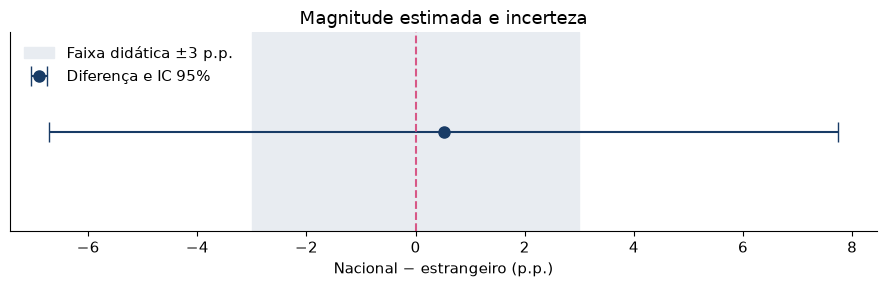

In [7]:
def tamanho_efeito(x, y):
    nx, ny = len(x), len(y)
    gl = nx+ny-2
    sp = np.sqrt(((nx-1)*np.var(x, ddof=1)+(ny-1)*np.var(y, ddof=1))/gl)
    if sp <= 0:
        raise ValueError("Desvio agrupado deve ser positivo.")
    d = (np.mean(x)-np.mean(y))/sp
    j = 1-3/(4*gl-1)
    return dict(desvio_agrupado=sp, d_cohen=d, g_hedges=j*d)

r5 = tamanho_efeito(x, y)
display(pd.Series(r5))
fig, ax = plt.subplots(figsize=(9, 3))
ax.axvspan(-LIMIAR_PP, LIMIAR_PP, color="#E8ECF1", label="Faixa didática ±3 p.p.")
delta = r4["delta_pp"]
ax.errorbar(delta, 0, xerr=[[delta-r4["ic_inf_pp"]], [r4["ic_sup_pp"]-delta]],
            fmt="o", color="#183B66", capsize=7, markersize=8, label="Diferença e IC 95%")
ax.axvline(0, linestyle="--", color="#D75887")
ax.set(yticks=[], xlabel="Nacional − estrangeiro (p.p.)", title="Magnitude estimada e incerteza")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
plt.show()

**Resultado:** d ≈ 0,0221 e g ≈ 0,0220. Os sinais positivos indicam média nacional maior no sorteio. A escala
padronizada deve ser lida com as distribuições; rótulos universais de "pequeno"
ou "grande" não definem importância econômica.

Embora a estimativa pontual esteja dentro de ±3 p.p., o IC não está contido nessa
faixa. A incerteza permite diferenças maiores. Não se conclui equivalência com
p > 0,05; um estudo de equivalência exigiria desenho e margens definidos previamente
e teste próprio, como TOST. O limiar deste exercício é fictício e não justifica
recomendação de investimento, solvência ou classificação de risco.

## Verificar sensibilidade com reamostragem

**Parte A — Bootstrap:**

**Parte B — Cobertura:**

,metodo,inferior_pp,superior_pp
0,Welch,-6.7108,7.7332
1,Bootstrap percentil,-6.5754,7.7643


media_populacao    20.5495
cobertura           0.9320
erro_monte_carlo    0.0080
dtype: float64

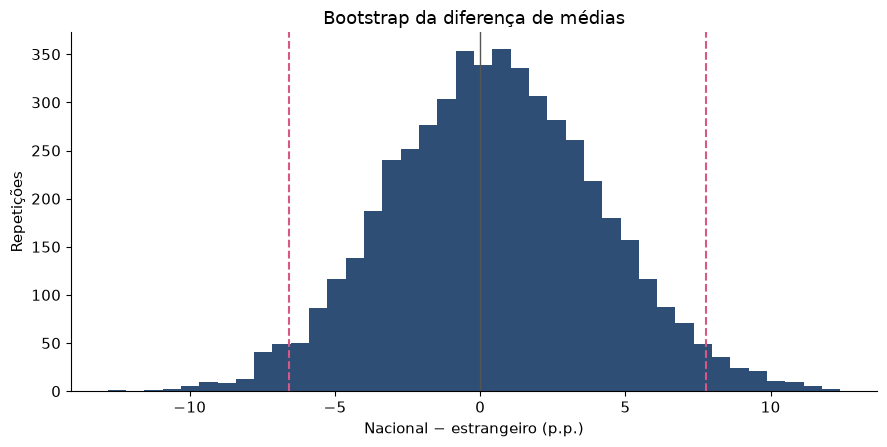

In [8]:
def bootstrap_delta(x, y, repeticoes=5000, semente=12345):
    gerador = np.random.default_rng(semente)
    bx = gerador.choice(x, size=(repeticoes, len(x)), replace=True).mean(axis=1)
    by = gerador.choice(y, size=(repeticoes, len(y)), replace=True).mean(axis=1)
    deltas = bx-by
    limites = np.quantile(deltas, [0.025, 0.975])
    return deltas, limites

def avaliar_cobertura(base, repeticoes=1000, semente=9876):
    populacao = base.loc[base.Tc.eq(2), "pl_ativo_pct"].to_numpy()
    mu = populacao.mean()
    gerador = np.random.default_rng(semente)
    simuladas = gerador.choice(populacao, size=(repeticoes, N_SORTEIOS), replace=True)
    medias = simuladas.mean(axis=1)
    erros = simuladas.std(axis=1, ddof=1)/np.sqrt(N_SORTEIOS)
    margem = stats.t.ppf(0.975, N_SORTEIOS-1)*erros
    cobertura = np.mean((medias-margem <= mu) & (mu <= medias+margem))
    erro_mc = np.sqrt(cobertura*(1-cobertura)/repeticoes)
    return dict(media_populacao=mu, cobertura=cobertura, erro_monte_carlo=erro_mc)

r6a = bootstrap_delta(x, y)
r6b = avaliar_cobertura(base)
display(pd.DataFrame({"metodo": ["Welch", "Bootstrap percentil"],
    "inferior_pp": [r4["ic_inf_pp"], r6a[1][0]],
    "superior_pp": [r4["ic_sup_pp"], r6a[1][1]]}))
display(pd.Series(r6b))
fig, ax = plt.subplots()
ax.hist(r6a[0], bins=40, color="#183B66", alpha=0.9)
for limite in r6a[1]:
    ax.axvline(limite, color="#D75887", linestyle="--")
ax.axvline(0, color="#555555", linewidth=1)
ax.set(title="Bootstrap da diferença de médias", xlabel="Nacional − estrangeiro (p.p.)",
       ylabel="Repetições")
fig.tight_layout()
plt.show()

**Resultados:** IC bootstrap ≈ [−6,5754; 7,7643] p.p.; cobertura t observada de
93,2%, com erro de Monte Carlo de aproximadamente 0,80 p.p. A distância para 95%
é de cerca de dois erros de Monte Carlo: há sinal de subcobertura neste laboratório,
coerente com a assimetria observada. Isso reforça que "95%" é uma cobertura nominal,
não garantia automática para qualquer distribuição.

Os dois intervalos podem diferir; ambos são aproximados. O bootstrap
percentil não é automaticamente superior em amostras pequenas ou assimétricas.
Concordância não elimina limitações; não use reamostragem como busca de significância.

A cobertura empírica não precisa ser exatamente 95%. Ela varia por erro de Monte
Carlo e pelo desempenho da aproximação t nessa população assimétrica. O erro
reportado refere-se à estimativa de cobertura, não à média de PL/ativo.
As mil repetições não acrescentam instituições nem validam o modelo para outras datas.

## Teste A/B: cenário separado e fictício

In [9]:
def tamanho_ab(p_a, p_b, alfa=0.05, poder=0.80):
    if not (0 < p_a < 1 and 0 < p_b < 1 and p_a != p_b):
        raise ValueError("Proporções devem estar entre 0 e 1 e ser diferentes.")
    if not (0 < alfa < 1 and 0.5 < poder < 1):
        raise ValueError("Parâmetros de significância/poder inválidos.")
    p_medio = (p_a+p_b)/2
    z_alfa = stats.norm.ppf(1-alfa/2)
    z_poder = stats.norm.ppf(poder)
    termo = z_alfa*np.sqrt(2*p_medio*(1-p_medio))
    termo += z_poder*np.sqrt(p_a*(1-p_a)+p_b*(1-p_b))
    return int(np.ceil(termo**2/(p_b-p_a)**2))

cenarios = []
for p_b in [0.14, 0.13]:
    n = tamanho_ab(0.12, p_b)
    cenarios.append({"referencia_pct": 12, "variante_pct": 100*p_b,
                     "efeito_pp": 100*(p_b-0.12),
                     "aumento_relativo_pct": 100*(p_b/0.12-1),
                     "n_por_grupo": n, "n_total": 2*n})
r7 = tamanho_ab(0.12, 0.14)
display(pd.DataFrame(cenarios))

,referencia_pct,variante_pct,efeito_pp,aumento_relativo_pct,n_por_grupo,n_total
0,12,14.0000,2.0000,16.6667,4438,8876
1,12,13.0000,1.0000,8.3333,17169,34338


**Resultados:** 4.438 clientes por grupo (8.876 no total) para +2 p.p.;
17.169 por grupo (34.338 no total) para +1 p.p., segundo a fórmula proposta.

**Interpretação:** de 12% para 14% são +2 p.p., equivalentes a aproximadamente
16,67% de aumento relativo. Detectar +1 p.p. requer muito mais observações.
O cálculo é uma aproximação para proporções independentes com alocação igual,
sem perdas, sem correção de continuidade e sem desenho por conglomerados.

Randomize por cliente elegível, uma única vez, mantendo a versão atribuída.
Defina conversão como conclusão da jornada em até sete dias da entrada; encerre
o recrutamento no n planejado e espere a maturação da janela de todos. A duração
de calendário depende do fluxo elegível, que não foi fornecido. Não pare ao aparecer p < 0,05.

Erro tipo I é rejeitar H₀ quando ela é verdadeira. Erro tipo II é não rejeitá-la
quando a alternativa especificada é verdadeira; poder 80% corresponde a β ≈ 20%
para o efeito planejado, sob as premissas. PL/ativo mede saldos contábeis, não
comportamento individual, e não pode fornecer uma taxa de conversão.

## Conclusões

In [10]:
medias_populacao = base.groupby("Tc").pl_ativo_pct.mean()
delta_populacao = medias_populacao.loc[2]-medias_populacao.loc[3]
nota_analitica = (
    f"No IF.data de junho/2026, o recorte B1 privado reúne {len(base)} unidades elegíveis; "
    f"uma foi excluída por saldos ausentes. Em 80 sorteios didáticos com reposição "
    f"por grupo, a diferença nacional menos estrangeiro de PL/ativo foi "
    f"{r4['delta_pp']:.2f} p.p. (IC 95%: {r4['ic_inf_pp']:.2f} a {r4['ic_sup_pp']:.2f}; "
    f"Welch, p={r4['p_valor']:.4f}). Não rejeitamos igualdade de médias, sem demonstrar "
    f"equivalência. O intervalo permite diferenças superiores ao limiar didático de 3 p.p. "
    f"Na base elegível completa, a diferença descritiva é {delta_populacao:.2f} p.p. "
    f"A incerteza calculada se refere aos sorteios, não ao setor inteiro. "
    f"A análise não identifica efeito causal do controle nem avalia solvência."
)
print(nota_analitica)
print("Palavras:", len(nota_analitica.split()))
display(pd.DataFrame({"grupo": [GRUPOS[2], GRUPOS[3]],
                     "media_populacao_pct": [medias_populacao.loc[2], medias_populacao.loc[3]]}))

No IF.data de junho/2026, o recorte B1 privado reúne 106 unidades elegíveis; uma foi excluída por saldos ausentes. Em 80 sorteios didáticos com reposição por grupo, a diferença nacional menos estrangeiro de PL/ativo foi 0.51 p.p. (IC 95%: -6.71 a 7.73; Welch, p=0.8890). Não rejeitamos igualdade de médias, sem demonstrar equivalência. O intervalo permite diferenças superiores ao limiar didático de 3 p.p. Na base elegível completa, a diferença descritiva é -2.85 p.p. A incerteza calculada se refere aos sorteios, não ao setor inteiro. A análise não identifica efeito causal do controle nem avalia solvência.
Palavras: 94


,grupo,media_populacao_pct
0,Privado nacional,20.5495
1,Controle estrangeiro,23.3960


**Correções:**
1. O p-valor é calculado sob H₀ e as premissas; não fornece a probabilidade de H₀.
2. O IC é um procedimento para estimar um parâmetro, não um intervalo que inclui 95% dos bancos.
3. Não rejeição é insuficiência de evidência contra H₀ no teste; equivalência exige outro desenho.
4. Sortear registros é amostragem; A/B requer atribuir aleatoriamente uma intervenção.

**Bônus:** médias da base elegível: nacional ≈ 20,5495% e estrangeiro ≈ 23,3960%;
diferença ≈ −2,8465 p.p. Esse contraste da população empírica é conhecido.
A diferença amostral varia com os sorteios; o IC busca cobrir o parâmetro conhecido
neste laboratório. Nem o contraste descritivo nem o teste identificam causalidade.

### Recorte da fonte

In [11]:
ATUALIZAR_DA_API = False

def reconstruir_recorte_bcb():
    from urllib.request import Request, urlopen
    from urllib.parse import urlparse
    from datetime import datetime, timezone

    raiz = "https://olinda.bcb.gov.br/olinda/servico/IFDATA/versao/v1/odata/"

    def consultar(caminho):
        url = raiz+caminho+"?$format=json"
        registros, visitadas = [], set()
        while url:
            if url in visitadas:
                raise ValueError("A API repetiu uma página; extração interrompida.")
            if urlparse(url).scheme != "https" or urlparse(url).hostname != "olinda.bcb.gov.br":
                raise ValueError("A API indicou próxima página em endereço inesperado.")
            visitadas.add(url)
            with urlopen(Request(url, headers={"Accept": "application/json"}), timeout=60) as r:
                pagina = json.load(r)
            if not isinstance(pagina.get("value"), list):
                raise ValueError("Resposta sem lista value; verifique a fonte.")
            registros.extend(pagina["value"])
            url = pagina.get("@odata.nextLink")
        if not registros:
            raise ValueError("A API não retornou dados.")
        return pd.DataFrame(registros)

    valores = consultar("IfDataValores(AnoMes=202606,TipoInstituicao=1,Relatorio='1')")
    cadastro = consultar("IfDataCadastro(AnoMes=202606)")
    n_original = len(valores)
    valores = valores.drop_duplicates()
    cadastro = cadastro.drop_duplicates()
    if valores.duplicated(["CodInst", "Conta"]).any():
        raise ValueError("Saldos divergentes por instituição/conta: revisar, não somar.")
    if cadastro.CodInst.duplicated().any():
        raise ValueError("Cadastro não é único por instituição.")
    if not valores.AnoMes.astype(str).eq("202606").all():
        raise ValueError("Data-base inesperada nos saldos.")
    if not cadastro.Data.astype(str).eq("202606").all():
        raise ValueError("Data-base inesperada no cadastro.")
    largos = valores.pivot(index="CodInst", columns="Conta", values="Saldo").reset_index()
    unidos = largos.merge(cadastro, on="CodInst", how="left", validate="one_to_one", indicator=True)
    sem_cadastro = unidos.loc[unidos._merge.ne("both"), "CodInst"].tolist()
    if sem_cadastro:
        print("Excluídas antes do filtro B1, por falta de cadastro:", sem_cadastro)
    unidos = unidos.loc[unidos._merge.eq("both")].copy()
    colunas = ["CodInst", "NomeInstituicao", "Data", "Tcb", "Td", "Tc", "Situacao",
               "CodConglomeradoPrudencial", "140220", "140246"]
    nova = unidos.loc[unidos.Tcb.str.upper().eq("B1"), colunas].copy()
    nova = nova.rename(columns={"Data": "data_base", "140220": "ativo_original", "140246": "pl_original"})
    nova = nova.sort_values("CodInst").reset_index(drop=True)
    cg = nova.CodConglomeradoPrudencial.fillna("")
    if not ((cg == "") | nova.CodInst.eq(cg)).all():
        raise ValueError("Recorte inclui integrantes de conglomerados: revisar consolidação.")
    print("Extração UTC:", datetime.now(timezone.utc).isoformat())
    print("Duplicatas exatas removidas:", n_original-len(valores))
    print("Unidades B1 na nova extração:", len(nova))
    return nova

if ATUALIZAR_DA_API:
    try:
        nova_base_bruta = reconstruir_recorte_bcb()
        display(nova_base_bruta.head())
    except Exception as exc:
        raise RuntimeError("Não foi possível atualizar. Os dados incorporados permanecem disponíveis.") from exc